|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[18] Token prediction accuracy</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

# to get wikitext dataset
from datasets import load_dataset

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50,
})

# **Part 1: Token prediction**

In [3]:
# load pretrained GPT-2 model and tokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')
model = AutoModelForCausalLM.from_pretrained('gpt2')
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [4]:
# text is paraphrased from https://en.wikipedia.org/wiki/Cubism
text = 'Cubism is an art movement that sparked innovations in music and architecture'
tokens = tokenizer.encode(text, return_tensors='pt')

for t in tokens[0]:
  print(f'Token {t:5} is "{tokenizer.decode(t)}"')

Token 43632 is "Cub"
Token  1042 is "ism"
Token   318 is " is"
Token   281 is " an"
Token  1242 is " art"
Token  3356 is " movement"
Token   326 is " that"
Token 16752 is " sparked"
Token 25438 is " innovations"
Token   287 is " in"
Token  2647 is " music"
Token   290 is " and"
Token 10959 is " architecture"


In [5]:
# forward pass
with torch.no_grad():
  outputs = model(tokens)

# find max-logit prediction for one token
whichToken = 5

# token logits are predictions for the subsequent token
token_logits = outputs.logits[0,whichToken,:]
maxlogit = torch.argmax(token_logits)

# visualize the logits and mark the predicted next-token
plt.figure(figsize=(12,4))
plt.plot(maxlogit,token_logits[maxlogit],'go',markersize=10)
plt.plot(token_logits,'.',markerfacecolor=[.9,.7,.7,.3])

plt.gca().set(title=f'Model prediction is "{tokenizer.decode(maxlogit)}" (target is "{tokenizer.decode(tokens[0,whichToken+1])}")',
              xlabel='Token index',ylabel='Model output logit',xlim=[-50,tokenizer.vocab_size+49])

plt.tight_layout()
plt.savefig('ch4_proj18_part1.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# **Part 2: Per-token predictions**

In [6]:
# find the token associated with a quote to insert into the sentences
quotetok = tokenizer.encode('"',return_tensors='pt')[0]

# initialize
accuracy = np.zeros(len(tokens[0]-1),dtype=int)

# loop over tokens
for idx in range(len(tokens[0])-1):

  # get max logit
  max_logit = torch.argmax( outputs.logits[0,idx,:] ,dim=-1).unsqueeze(0)

  # get the max prediction
  accuracy[idx] = max_logit[0] == tokens[0][idx+1]

  # reconstruct the sentence tokens
  sentence = torch.cat(
      (tokens[0][:idx+1],              # original first few tokens
       quotetok, max_logit, quotetok), # predicted token, padded by quotes
      dim=-1)

  # decode and print
  print(f"{'X✓'[accuracy[idx]]}: {tokenizer.decode(sentence)}")

print(f'\nModel correctly predicted {accuracy.sum()}/{len(accuracy)} tokens ({accuracy.mean():.2%})')

X: Cub"."
X: Cubism","
X: Cubism is" a"
X: Cubism is an" ideology"
X: Cubism is an art" form"
✓: Cubism is an art movement" that"
X: Cubism is an art movement that" seeks"
X: Cubism is an art movement that sparked" the"
✓: Cubism is an art movement that sparked innovations" in"
X: Cubism is an art movement that sparked innovations in" the"
X: Cubism is an art movement that sparked innovations in music","
X: Cubism is an art movement that sparked innovations in music and" art"

Model correctly predicted 2/13 tokens (15.38%)


# **Part 3: Top-k predicted tokens**

In [7]:
k = 10

topk = torch.topk(token_logits,k,dim=-1) # same token_logits variable (from whichToken) defined in Part 1

print('Original text:\n  ',text,'\n\nGPT2 predictions:')

for t in topk.indices:

  # reconstruct the sentence tokens
  sentence = torch.cat(
      (tokens[0][:whichToken+1],            # original first few tokens
       quotetok, t.unsqueeze(0), quotetok), # predicted token
      dim=-1)

  # decode and print
  print('  ',tokenizer.decode(sentence))

Original text:
   Cubism is an art movement that sparked innovations in music and architecture 

GPT2 predictions:
   Cubism is an art movement" that"
   Cubism is an art movement","
   Cubism is an art movement"."
   Cubism is an art movement" and"
   Cubism is an art movement" which"
   Cubism is an art movement" in"
   Cubism is an art movement" based"
   Cubism is an art movement" founded"
   Cubism is an art movement" of"
   Cubism is an art movement" with"


# **Part 4: Token prediction accuracy in wikitext**

In [8]:
wikitxt = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1', split='test')
tokens = tokenizer.encode('\n\n'.join(wikitxt['text']), return_tensors='pt')
num_tokens = torch.numel(tokens)

print(f'There are {num_tokens:,} tokens in the wikitext dataset')

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (287644 > 1024). Running this sequence through the model will result in indexing errors


There are 287,644 tokens in the wikitext dataset


In [9]:
# here's what one sample looks like
wikitxt[1112]['text']

" On May 24 , 2008 , the Dodgers bought Kershaw 's minor @-@ league contract , and he was added to the active roster . Sportswriter Tony Jackson called Kershaw 's debut the most anticipated start by a Dodgers pitcher since Hideo Nomo 's major league debut during the 1995 season . He made his debut on May 25 , starting against the St. Louis Cardinals . He struck out the first batter he faced , Skip Schumaker , the first of seven strikeouts in the game , in which he pitched six innings and allowed two runs . When he debuted , Kershaw was the youngest player in MLB , a title he held for one full year . \n"

In [10]:
max_seq_len = model.config.n_positions
print(f'The model can accept up to {max_seq_len} tokens per sequence per forward pass.')

The model can accept up to 1024 tokens per sequence per forward pass.


In [11]:
# initialize
accuracy = np.zeros(max_seq_len-1,dtype=int)

# forward pass
with torch.no_grad():
  outputs = model(tokens[:,:max_seq_len])

# loop over tokens
for idx in range(max_seq_len-1):

  # get max logit
  max_logit = torch.argmax( outputs.logits[0,idx,:] ,dim=-1)

  # get the max prediction
  accuracy[idx] = max_logit == tokens[0][idx+1]

print(f'\nModel correctly predicted {accuracy.sum()}/{len(accuracy)} tokens ({accuracy.mean():.2%})')


Model correctly predicted 528/1023 tokens (51.61%)


In [12]:
# the text that was assessed
print(tokenizer.decode(tokens[0,:max_seq_len]))



 = Robert Boulter = 




 Robert Boulter is an English film , television and theatre actor . He had a guest @-@ starring role on the television series The Bill in 2000 . This was followed by a starring role in the play Herons written by Simon Stephens , which was performed in 2001 at the Royal Court Theatre . He had a guest role in the television series Judge John Deed in 2002 . In 2004 Boulter landed a role as " Craig " in the episode " Teddy 's Story " of the television series The Long Firm ; he starred alongside actors Mark Strong and Derek Jacobi . He was cast in the 2005 theatre productions of the Philip Ridley play Mercury Fur , which was performed at the Drum Theatre in Plymouth and the Menier Chocolate Factory in London . He was directed by John Tiffany and starred alongside Ben Whishaw , Shane Zaza , Harry Kent , Fraser Ayres , Sophie Stanton and Dominic Hall . 


 In 2006 , Boulter starred alongside Whishaw in the play Citizenship written by Mark Ravenhill . He appeared on 

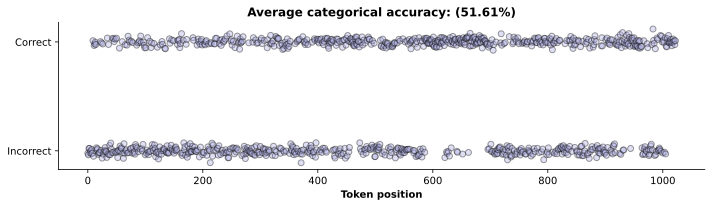

In [13]:
# visualize
plt.figure(figsize=(10,3))
plt.plot(np.random.normal(0,.03,len(accuracy))+accuracy,'ko',markerfacecolor=[.7,.7,.9,.4])
plt.gca().set(xlabel='Token position',yticks=[0,1],yticklabels=['Incorrect','Correct'],
              title=f'Average categorical accuracy: ({accuracy.mean():.2%})')

plt.tight_layout()
plt.savefig('ch4_proj18_part4.png')
plt.show()